In [35]:
import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px
import pandas as pd

from src import cleaning
from src import geo
from src import diagnostics

In [2]:
raw = cleaning.load_raw("paris")
with_pos = cleaning.remove_missing_positions(raw)
deduped = cleaning.remove_duplicates(with_pos)


print(len(raw))
print(len(with_pos))
print(len(deduped))

235323
235323
190895


In [3]:
deduped = deduped.sort_values(by=["icao24", "time_position"]).reset_index(drop=True)
deduped["gap_s"] = deduped.groupby("icao24")["time_position"].diff()

print(deduped["gap_s"].describe())

print("\nLargest gaps (seconds):")
print(deduped["gap_s"].sort_values(ascending=False).head(15))

count    188170.000000
mean        782.622076
std        8664.731573
min           1.000000
25%          22.000000
50%          25.000000
75%          29.000000
max      408041.000000
Name: gap_s, dtype: float64

Largest gaps (seconds):
13845     408041.0
152622    349187.0
120628    346394.0
133567    345468.0
30495     336811.0
173767    334794.0
89482     331598.0
8855      327172.0
21998     324618.0
3537      322862.0
177595    320299.0
187260    320245.0
177921    317119.0
120756    316126.0
114955    314688.0
Name: gap_s, dtype: float64


In [4]:
COLUMNS = ["icao24", "callsign", "time_position", "gap_s",
           "latitude", "longitude", "geo_altitude", "on_ground", "vertical_rate"]

ambiguous = deduped[(deduped["gap_s"] > 300) & (deduped["gap_s"] < 3600)]
print(f"{len(ambiguous)} ambiguous gaps\n")
print()

for idx in ambiguous.index:
    print(f"gap of {deduped.loc[idx, 'gap_s'] / 60:.1f} min")
    print(deduped.loc[idx - 1 : idx, COLUMNS].to_string())
    print()

700 ambiguous gaps


gap of 6.3 min
     icao24  callsign  time_position  gap_s  latitude  longitude  geo_altitude  on_ground  vertical_rate
287  01028b               1795186084   14.0   49.0207     2.5570           NaN       True            NaN
288  01028b  MSR800       1795186465  381.0   49.0203     2.5076        525.78      False          14.96

gap of 15.3 min
      icao24  callsign  time_position  gap_s  latitude  longitude  geo_altitude  on_ground  vertical_rate
1403  0200ea  RAM740X      1795203417   73.0   48.7311     2.3752           NaN       True            NaN
1404  0200ea  RANM781S     1795204338  921.0   48.7312     2.3752           NaN       True            NaN

gap of 8.9 min
      icao24  callsign  time_position  gap_s  latitude  longitude  geo_altitude  on_ground  vertical_rate
1456  0200ea  RANM781S     1795207833  185.0   48.7311     2.3752           NaN       True            NaN
1457  0200ea               1795208366  533.0   48.7312     2.3752           NaN       

In [5]:
for threshold in [60, 300, 600, 900, 1200, 3600]:
    count = (deduped["gap_s"] > threshold).sum()
    print(f"gaps > {threshold / 60:>5.0f} min: {count}")

gaps >     1 min: 8102
gaps >     5 min: 4782
gaps >    10 min: 4555
gaps >    15 min: 4466
gaps >    20 min: 4408
gaps >    60 min: 4082


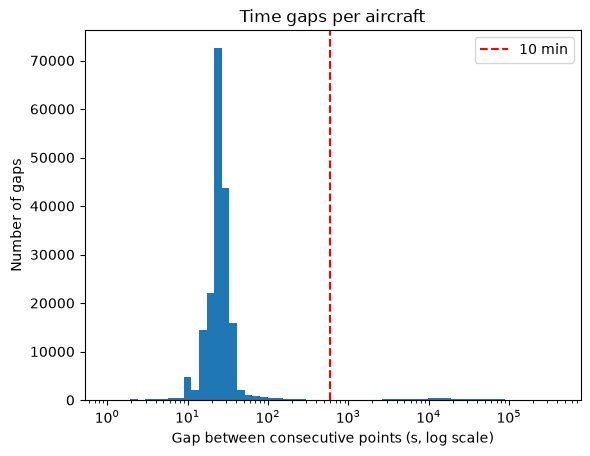

In [6]:
gaps = deduped["gap_s"].dropna()
bins = np.logspace(0, np.log10(gaps.max()), 60)

plt.hist(gaps, bins=bins)
plt.xscale("log")
plt.xlabel("Gap between consecutive points (s, log scale)")
plt.ylabel("Number of gaps")
plt.title("Time gaps per aircraft")
plt.axvline(600, color="red", linestyle="--", label="10 min")
plt.legend()
plt.show()

In [7]:
grouped_flights = cleaning.split_flights(deduped)

In [8]:
final_point = grouped_flights.groupby("flight_id").tail(1).copy()
final_point["distance_to_cdg_km"] = geo.haversine_km(final_point["latitude"], final_point["longitude"], geo.CDG_COORDS["lat"], geo.CDG_COORDS["lon"])

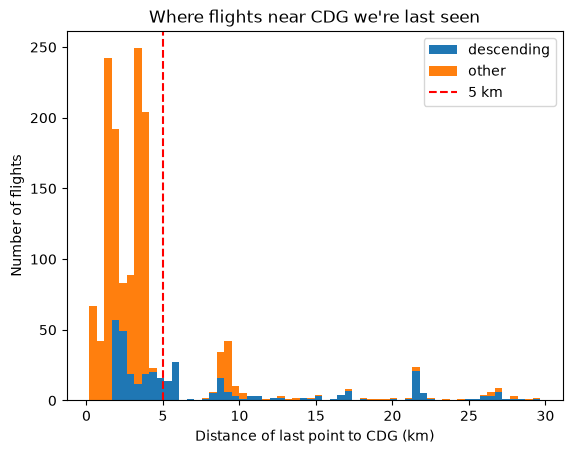

In [9]:
near = final_point[final_point["distance_to_cdg_km"] < 30]

descending = near[near["vertical_rate"] < 0]
other = near[~(near["vertical_rate"] < 0)]

plt.hist([descending["distance_to_cdg_km"], other["distance_to_cdg_km"]], bins=60, stacked=True, label=["descending", "other"])
plt.xlabel("Distance of last point to CDG (km)")
plt.ylabel("Number of flights")
plt.title("Where flights near CDG we're last seen")
plt.axvline(5, color="red", linestyle="--", label="5 km")
plt.legend()
plt.show()

In [10]:
MAX_DISTANCE_KM = 7
MAX_ALTITUDE_M = 500
MIN_AIRBORNE_ALT_M = 1000

airborne_flight_ids = grouped_flights[grouped_flights["geo_altitude"] > MIN_AIRBORNE_ALT_M]["flight_id"].unique()

is_close = final_point["distance_to_cdg_km"] < MAX_DISTANCE_KM
is_low = (final_point["on_ground"]) | (final_point["geo_altitude"] < MAX_ALTITUDE_M)
was_airborne = final_point["flight_id"].isin(airborne_flight_ids)

arrival_endpoints = final_point[is_close & is_low & was_airborne]
cdg_arrivals = grouped_flights[grouped_flights["flight_id"].isin(arrival_endpoints["flight_id"])]

n_flights = cdg_arrivals["flight_id"].nunique()
n_points = len(cdg_arrivals)

print(f"Flights checked: {len(final_point)}")
print(f"ending within {MAX_DISTANCE_KM} km: {is_close.sum()}")
print(f"and on ground/low: {(is_close & is_low).sum()}")
print(f"and were airborne: {len(arrival_endpoints)}")
print(f"Points in arrival tracks: {n_points} (~{n_points / n_flights:.0f} per flight)")

Flights checked: 7280
ending within 7 km: 1249
and on ground/low: 1244
and were airborne: 1156
Points in arrival tracks: 44430 (~38 per flight)


In [11]:
print(cleaning.keep_arrivals(grouped_flights, geo.CDG_COORDS)["flight_id"].nunique())

1156


In [12]:
grouped = cdg_arrivals.groupby("flight_id")

prev_lat = grouped["latitude"].shift()
prev_lon = grouped["longitude"].shift()

step_km = geo.haversine_km(
	prev_lat,
	prev_lon,
	cdg_arrivals["latitude"],
	cdg_arrivals["longitude"]
)

step_s = grouped["time_position"].diff()
implied_speed_kmh = step_km / (step_s / 3600)
vertical_speed_ms = grouped["geo_altitude"].diff() / step_s

print(f"Implied speed (km/h): {implied_speed_kmh.describe()}")
print(f"Vertical speed (m/s): {vertical_speed_ms.describe()}")

Implied speed (km/h): count    43274.000000
mean       382.076836
std        164.856521
min          0.000000
25%        272.417557
50%        392.652531
75%        498.929364
max       1642.793190
dtype: float64
Vertical speed (m/s): count    39321.000000
mean        -3.836577
std          2.556902
min        -38.100000
25%         -5.275385
50%         -3.962400
75%         -2.344615
max         17.689286
dtype: float64


In [13]:
inspect = cdg_arrivals.copy()
inspect["step_s"] = step_s
inspect["step_km"] = step_km
inspect["speed_kmh"] = implied_speed_kmh
inspect["vspeed_ms"] = vertical_speed_ms

COLS = ["flight_id", "time_position", "step_s", "step_km", "speed_kmh",
        "vspeed_ms", "latitude", "longitude", "geo_altitude", "on_ground"]

In [14]:
def show_with_neighbours(table, idx, cols=COLS):
    print(table.loc[idx - 1 : idx + 1, cols].to_string())
    print()

In [15]:
print("Top 5 highest speeds")
for idx in inspect["speed_kmh"].nlargest(5).index:
	show_with_neighbours(inspect, idx)
 
print("Points below -20 m/s")
for idx in inspect[inspect["vspeed_ms"] < -20].index:
    show_with_neighbours(inspect, idx)

climb_flight = inspect.loc[inspect["vspeed_ms"].idxmax(), "flight_id"]
one = inspect[inspect["flight_id"] == climb_flight]

print("Positive climb flight")
print(one)

Top 5 highest speeds
      flight_id  time_position  step_s    step_km    speed_kmh  vspeed_ms  latitude  longitude  geo_altitude  on_ground
17491  347308_1     1795222450    26.0  10.877170  1506.069699 -12.602308   48.9104     2.3537       3695.70      False
17492  347308_1     1795222475    25.0  11.408286  1642.793190 -14.020800   48.9169     2.5095       3345.18      False
17493  347308_1     1795222499    24.0  10.377418  1556.612644 -20.320000   48.9184     2.6515       2857.50      False

      flight_id  time_position  step_s    step_km    speed_kmh  vspeed_ms  latitude  longitude  geo_altitude  on_ground
17492  347308_1     1795222475    25.0  11.408286  1642.793190 -14.020800   48.9169     2.5095       3345.18      False
17493  347308_1     1795222499    24.0  10.377418  1556.612644 -20.320000   48.9184     2.6515       2857.50      False
17494  347308_1     1795222525    26.0  10.420780  1442.877242 -13.774615   48.9198     2.7941       2499.36      False

      flight_id  

In [16]:
median_flights_speed = inspect.groupby(by="flight_id")["speed_kmh"].median()
median_speed = median_flights_speed.median()

candidate_flight = median_flights_speed.sub(median_speed).abs().idxmin()

print(f"Median flight speed: {median_speed:.1f}")
print(candidate_flight)
median_flights_speed.sort_values(ascending=False).head(10)

Median flight speed: 402.0
398579_6


flight_id
347308_1    1057.233262
440d93_1     829.363151
440b2f_1     812.575890
392af8_1     775.095792
440051_5     750.780246
440ced_1     668.189479
440102_1     663.881406
a0996b_1     644.045632
39e68e_2     633.295444
40756b_1     633.115995
Name: speed_kmh, dtype: float64

In [17]:
flight_ids = ["347308_1", "440d93_1", "44a6e4_1", "398579_6"]

for flight_id in flight_ids:
    print(f"Flight: {flight_id}")
    print(inspect.loc[inspect["flight_id"] == flight_id, ["time_position", "speed_kmh", "callsign"]].assign(
		velocity_kmh=inspect["velocity"] * 3.6,
		ratio=inspect["speed_kmh"] / (inspect["velocity"] * 3.6)
	))

Flight: 347308_1
       time_position    speed_kmh  callsign  velocity_kmh     ratio
17487     1795222349          NaN  SWT5614        644.400       NaN
17488     1795222373  1499.634694  SWT5614        628.632  2.385553
17489     1795222397  1530.280688  SWT5614        587.700  2.603847
17490     1795222424  1412.912294  SWT5614        594.756  2.375617
17491     1795222450  1506.069699  SWT5614        587.196  2.564850
17492     1795222475  1642.793190  SWT5614        587.124  2.798034
17493     1795222499  1556.612644  SWT5614        585.288  2.659567
17494     1795222525  1442.877242  SWT5614        546.372  2.640833
17495     1795222540  1382.012610  SWT5614        538.992  2.564069
17496     1795222573  1043.874397  SWT5614        424.836  2.457123
17497     1795222599  1057.233262  SWT5614        400.752  2.638123
17498     1795222627   981.706897  SWT5614        299.160  3.281545
17499     1795222648   806.713698  SWT5614        269.316  2.995417
17500     1795222677   696.9287

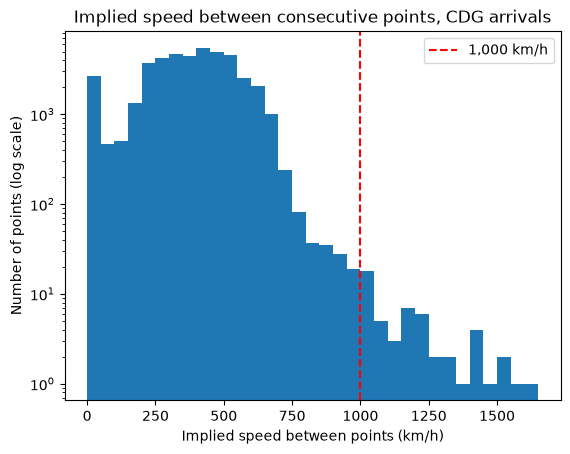

In [18]:
speeds = implied_speed_kmh.dropna()
bins = np.arange(0, speeds.max() + 50, 50)

plt.hist(speeds, bins=bins)
plt.yscale("log")
plt.xlabel("Implied speed between points (km/h)")
plt.ylabel("Number of points (log scale)")
plt.title("Implied speed between consecutive points, CDG arrivals")
plt.axvline(1000, color="red", linestyle="--", label="1,000 km/h")
plt.legend()
plt.show()

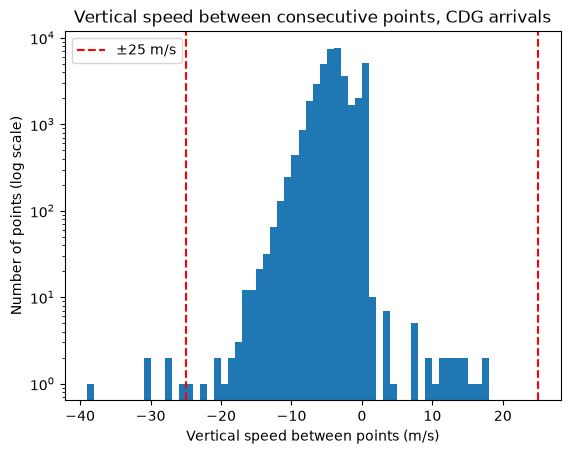

In [19]:
vertical = vertical_speed_ms.dropna()
vertical_bins = np.arange(np.floor(vertical.min()), np.ceil(vertical.max()) + 1, 1)

plt.hist(vertical, bins=vertical_bins)
plt.yscale("log")
plt.xlabel("Vertical speed between points (m/s)")
plt.ylabel("Number of points (log scale)")
plt.title("Vertical speed between consecutive points, CDG arrivals")
plt.axvline(-25, color="red", linestyle="--", label="±25 m/s")
plt.axvline(25, color="red", linestyle="--")
plt.legend()
plt.show()

0.48054991116760665


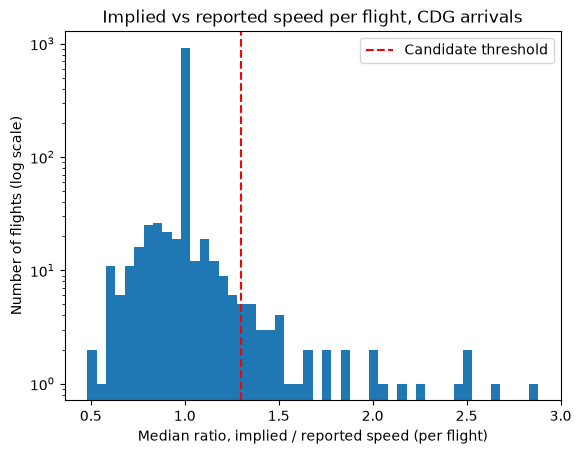

In [20]:
inspect["velocity_kmh"] = inspect["velocity"] * 3.6
inspect["ratio"] = inspect["speed_kmh"] / inspect["velocity_kmh"]

medians = inspect[inspect["velocity_kmh"] >= 50].groupby("flight_id")["ratio"].median().dropna()
median_bins = np.arange(medians.min(), medians.max() + 0.05, 0.05)

print(medians.min())

plt.hist(medians, bins=median_bins)
plt.yscale("log")
plt.axvline(1.3, color="red", linestyle="--", label="Candidate threshold")
plt.title("Implied vs reported speed per flight, CDG arrivals")
plt.ylabel("Number of flights (log scale)")
plt.xlabel("Median ratio, implied / reported speed (per flight)")
plt.legend()
plt.show()

In [22]:
cols = ["speed_kmh", "velocity_kmh", "ratio", "step_s"]
lowest_ratio_flight = medians.idxmin()
flight_rows = inspect[inspect["flight_id"] == lowest_ratio_flight]

print(flight_rows[cols + ["flight_id"]])

fig = px.line_map(
    data_frame=flight_rows,
    lat="latitude",
    lon="longitude",
    center={"lat": 48.86, "lon": 2.35},
    zoom=8,
	hover_data=cols + ["geo_altitude"],
	map_style="carto-positron"
)

fig.show()

        speed_kmh  velocity_kmh     ratio  step_s flight_id
34969         NaN       413.964       NaN     NaN  392af5_2
34970  201.040742       416.664  0.482501     9.0  392af5_2
34971  223.740835       425.700  0.525583    38.0  392af5_2
34972  202.385424       427.320  0.473616    17.0  392af5_2
34973  218.181123       422.208  0.516762    34.0  392af5_2
34974  192.861061       414.360  0.465443    27.0  392af5_2
34975  191.799724       407.628  0.470526    22.0  392af5_2
34976  184.455469       398.412  0.462977    28.0  392af5_2
34977  166.237848       394.560  0.421325    15.0  392af5_2
34978  176.635383       381.672  0.462794    33.0  392af5_2
34979  187.789610       377.352  0.497651    20.0  392af5_2
34980  169.060452       374.220  0.451768    29.0  392af5_2
34981  176.711914       376.056  0.469909    27.0  392af5_2
34982  222.035395       377.712  0.587843    11.0  392af5_2
34983  186.860947       382.464  0.488571    36.0  392af5_2
34984  171.799911       385.416  0.44575

In [33]:
low_ratio_flight = inspect[inspect["flight_id"] == "392af5_2"].copy()

snap_step_s = low_ratio_flight["snapshot_time"].diff()
snap_implied_speed_kmh = low_ratio_flight["step_km"] / (snap_step_s.dt.total_seconds() / 3600)

low_ratio_flight["snap_ratio"] = snap_implied_speed_kmh / low_ratio_flight["velocity_kmh"]

print(f"ratio using 'time_position': {low_ratio_flight["ratio"].median()}")
print(f"ratio using 'snapshot_time': {low_ratio_flight["snap_ratio"].median()}")

ratio using 'time_position': 0.48054991116760665
ratio using 'snapshot_time': 0.47539111375766385


In [37]:
high_ratio_flight = inspect[inspect["flight_id"] == "347308_1"].copy()
ratio = diagnostics.speed_ratio(high_ratio_flight, "snapshot_time")

print(f"ratio using 'time_position': {high_ratio_flight["ratio"].median()}")
print(f"ratio using 'snapshot_time': {ratio.median()}")

ratio using 'time_position': 2.603846670285787
ratio using 'snapshot_time': 2.6158028596208354


In [46]:
cdg_arrivals_ratio = diagnostics.speed_ratio(cdg_arrivals)
ratio_medians = cdg_arrivals_ratio.groupby(cdg_arrivals["flight_id"]).median()

ranges = [(0.9, 1.1), (0.8, 1.25), (0.75, 1.33)]

for low, high in ranges:
	outside = (ratio_medians < low) | (ratio_medians > high)
	print(f"Outside {low}-{high}: {outside.sum()} flights ({outside.mean() * 100:.1f}%)")

Outside 0.9-1.1: 182 flights (15.7%)
Outside 0.8-1.25: 100 flights (8.7%)
Outside 0.75-1.33: 69 flights (6.0%)


In [48]:
borderline = ratio_medians[ratio_medians.between(0.75, 0.8) | ratio_medians.between(1.25, 1.33)]

for flight_id in borderline.sample(4).index:
    rows = cdg_arrivals[cdg_arrivals["flight_id"] == flight_id]
    ratio = diagnostics.speed_ratio(rows)
    
    print(f"Flight {flight_id} ({rows["callsign"].iloc[0]}), median ratio {ratio.median():.2f}")
    print(pd.DataFrame({
		"velocity_kmh": rows["velocity"] * 3.6,
		"ratio": ratio
	}).to_string())

Flight 39856a_3 (HOP36EH ), median ratio 1.31
       velocity_kmh     ratio
53751       460.404       NaN
53752       457.812  1.275939
53753       460.404  1.251528
53754       464.472  1.341601
53755       463.392  1.269703
53756       440.784  1.482654
53757       401.148  1.494323
53758       395.964  1.313426
53759       396.576  1.297051
53760       367.380  1.334028
53761       361.944  1.340830
53762       323.280  1.367716
53763       310.212  1.313328
53764       245.160  1.430565
53765       208.080  1.280273
53766       208.260  1.221295
53767       213.768  1.248717
53768       213.768  1.267008
53769       213.480  1.159770
53770        70.380  3.272641
Flight 0201c2_1 (RAM788H ), median ratio 0.80
      velocity_kmh     ratio
3307       622.044       NaN
3308       622.044  0.941028
3309       626.184  0.874299
3310       624.528  0.870785
3311       618.732  0.895981
3312       618.732  0.793673
3313       644.760  0.817042
3314       658.908  0.805605
3315       665.17